In [1]:
!pip -q install -U transformers accelerate sentencepiece "pandas==2.2.3"

In [2]:
import pandas as pd
import torch
from week3_react import REACT_SYSTEM, MODEL_NAME, safe_python_exec, load_model, safe_calculate, baseline_answer, react_answer, run_experiment
print("Model:", MODEL_NAME)
print("CUDA available:", torch.cuda.is_available())

Model: Qwen/Qwen2.5-3B-Instruct
CUDA available: True


In [3]:
from datasets import load_dataset
import pandas as pd

ds = load_dataset("HuggingFaceH4/MATH-500")

README.md:   0%|          | 0.00/412 [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/447k [00:00<?, ?B/s]

Generating test split:   0%|          | 0/500 [00:00<?, ? examples/s]

In [4]:
ds.shape

{'test': (500, 6)}

In [5]:
df = pd.DataFrame(ds['test'])[['problem', 'answer', 'subject']]
df = df[df['subject'] == 'Number Theory']
display(df.head(10))

,problem,answer,subject
3,How many positive whole-number divisors does 1...,9,Number Theory
6,What is the smallest positive perfect cube tha...,27,Number Theory
10,What is the least positive integer multiple of...,2220,Number Theory
12,"The proper divisors of 12 are 1, 2, 3, 4 and 6...",284,Number Theory
30,Find the product of $6_8 \cdot 7_8.$ Express y...,52_8,Number Theory
35,"If $n \equiv 2 \pmod{7}$, then find the remain...",3,Number Theory
39,What is the result when the greatest common fa...,23,Number Theory
50,You have seven bags of gold coins. Each bag ha...,203,Number Theory
70,Compute $58_9 - 18_9.$ Express your answer in ...,40_9,Number Theory
71,The binary number $10101001110_{2}$ is equal t...,2516_8,Number Theory


In [6]:
# Filter the dataframe for answers containing LaTeX elements like \left, \right, \frac, or backslashes indicating equations
math_pattern = r'\\left|\\right|\\frac|\\pi|\\[a-zA-Z]+'
filtered_df = df[~df['answer'].str.contains(math_pattern, na=False, regex=True)]
filtered_df = filtered_df[~filtered_df['problem'].str.contains(math_pattern, na=False, regex=True)]
print(f"Found {len(filtered_df)} rows matching the criteria.")

filtered_df.reset_index(drop=True)
filtered_df.index += 1
filtered_df.index.name = 'id'

display(filtered_df.head(10)),

Found 37 rows matching the criteria.


,problem,answer,subject
id,,,
4,How many positive whole-number divisors does 1...,9,Number Theory
7,What is the smallest positive perfect cube tha...,27,Number Theory
11,What is the least positive integer multiple of...,2220,Number Theory
13,"The proper divisors of 12 are 1, 2, 3, 4 and 6...",284,Number Theory
40,What is the result when the greatest common fa...,23,Number Theory
51,You have seven bags of gold coins. Each bag ha...,203,Number Theory
71,Compute $58_9 - 18_9.$ Express your answer in ...,40_9,Number Theory
72,The binary number $10101001110_{2}$ is equal t...,2516_8,Number Theory
90,"Find the greatest common divisor of $3339$, $2...",21,Number Theory


(None,)

In [7]:
filtered_df_renamed = filtered_df.rename(columns={'problem': 'question'})
TASK = filtered_df_renamed.reset_index().to_dict(orient='records')

In [8]:
TASK[:2]

[{'id': 4,
  'question': 'How many positive whole-number divisors does 196 have?',
  'answer': '9',
  'subject': 'Number Theory'},
 {'id': 7,
  'question': 'What is the smallest positive perfect cube that can be written as the sum of three consecutive integers?',
  'answer': '27',
  'subject': 'Number Theory'}]

In [9]:
tokenizer, model = load_model()

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

In [10]:

tests = [
    # Divisor count of 196
    "len([i for i in range(1, 197) if 196 % i == 0])",

    # Minimum cube
    "min(k**3 for k in range(3, 10, 3))",

    # Maximum
    "max([10, 20, 30, 40])",

    # All positive
    "all(x > 0 for x in [1, 2, 3])",

    # Smallest 0-and-2 multiple of 30
    """
numbers = [
    i for i in range(2, 10000)
    if all(d in "02" for d in str(i))
    and i % 30 == 0
]
min(numbers)
"""
]

for test in tests:
    print("Expression:", test.strip())
    print("Observation:", safe_python_exec(test))
    print("-" * 50)


Expression: len([i for i in range(1, 197) if 196 % i == 0])
Observation: 9
--------------------------------------------------
Expression: min(k**3 for k in range(3, 10, 3))
Observation: 27
--------------------------------------------------
Expression: max([10, 20, 30, 40])
Observation: 40
--------------------------------------------------
Expression: all(x > 0 for x in [1, 2, 3])
Observation: True
--------------------------------------------------
Expression: numbers = [
    i for i in range(2, 10000)
    if all(d in "02" for d in str(i))
    and i % 30 == 0
]
min(numbers)
Observation: 2220
--------------------------------------------------


In [11]:
for expression in ["2 * 2", "2 / 24", "45 * 4 + 10"]:
  print(f"{expression} -> {safe_calculate(expression)}")

2 * 2 -> 4
2 / 24 -> 0.08333333333333333
45 * 4 + 10 -> 190


3. Baseline: Direct Reasoning
The model receives each question and is asked to answer directly, without access to a tool. This provides the comparison point for the ReAct condition.

In [12]:
baseline_preview=[]
for task in TASK[:10]:
  answer = baseline_answer(tokenizer, model, task['question'])
  baseline_preview.append({"task_id": task['id'], 'expected': task['answer'], 'model_answer': answer})

pd.DataFrame(baseline_preview)

,task_id,expected,model_answer
0,4,9,To find how many positive whole-number divisor...
1,7,27,"To solve this, we need to find a perfect cube ..."
2,11,2220,"To solve this, we need to find the smallest nu..."
3,13,284,"First, let's find the proper divisors of 284. ..."
4,40,23,"First, we need to find the greatest common fac..."
5,51,203,Let's denote the number of coins in each of th...
6,71,40_9,To solve \(58_9 - 18_9\) and express the answe...
7,72,2516_8,"To convert from binary to octal, we can group ..."
8,90,21,To find the greatest common divisor (GCD) of 3...
9,108,9,"To solve this, we first identify the sets invo..."


4. ReAct: Interleaved Reasoning & Action
The loop follows: Question → Model Decision → Tool Call (if chosen) → Observation → Model Decision → Final Answer

In [13]:
for each in TASK[:3]:
  print("\n\n==============================")
  print(f"ID: {each['id']}")
  print(f"Question: {each['question']}")
  print(f"Expected Answer: {each['answer']}")



ID: 4
Question: How many positive whole-number divisors does 196 have?
Expected Answer: 9


ID: 7
Question: What is the smallest positive perfect cube that can be written as the sum of three consecutive integers?
Expected Answer: 27


ID: 11
Question: What is the least positive integer multiple of 30 that can be written with only the digits 0 and 2?
Expected Answer: 2220


In [14]:
react_preview=[]
for task in TASK[:15]:
    result=react_answer(tokenizer,model,task["question"])
    react_preview.append({"id":task["id"],"expected":task["answer"],"react_answer":result["answer"],"tool_calls":result["tool_calls"]})
pd.DataFrame(react_preview)

,id,expected,react_answer,tool_calls
0,4,9,9,1
1,7,27,216,1
2,11,2220,60,1
3,13,284,NO FINAL ANSWER,2
4,40,23,NO FINAL ANSWER,2
5,51,203,NO FINAL ANSWER,2
6,71,40_9,NO FINAL ANSWER,2
7,72,2516_8,NO FINAL ANSWER,2
8,90,21,NO FINAL ANSWER,2
9,108,9,9,0


5. Evaluation & Comparison
Both conditions are now run on the full fixed task set. The primary metric is exact numerical correctness after simple answer normalisation; ReAct tool usage is also recorded.

In [15]:
len(TASK)

37

In [16]:
results=run_experiment(tokenizer,model,TASK,results_path="week3_results.json")
results_df=pd.DataFrame([{
    "id":r["id"],"expected":r["expected"],"baseline_correct":r["baseline_correct"],
    "react_correct":r["react_correct"],"tool_calls":r["tool_calls"]} for r in results])
results_df

Running 4...
Running 7...
Running 11...
Running 13...
Running 40...
Running 51...
Running 71...
Running 72...
Running 90...
Running 108...
Running 128...
Running 142...
Running 150...
Running 161...
Running 198...
Running 202...
Running 209...
Running 218...
Running 222...
Running 272...
Running 279...
Running 281...
Running 295...
Running 298...
Running 310...
Running 339...
Running 351...
Running 376...
Running 404...
Running 407...
Running 416...
Running 424...
Running 458...
Running 463...
Running 466...
Running 478...
Running 488...

Results saved to: week3_results.json


,id,expected,baseline_correct,react_correct,tool_calls
0,4,9,False,True,1
1,7,27,False,False,1
2,11,2220,False,False,1
3,13,284,False,False,2
4,40,23,False,False,2
5,51,203,False,False,2
6,71,40_9,True,False,2
7,72,2516_8,False,False,2
8,90,21,False,False,2
9,108,9,False,True,0


### Visualizing the Experiment Results
We can compare the overall accuracy of both systems (Baseline vs. ReAct) and inspect how the number of tool calls correlates with correctness using side-by-side bar plots.

Baseline Accuracy: 8.11%
ReAct Accuracy: 18.92%


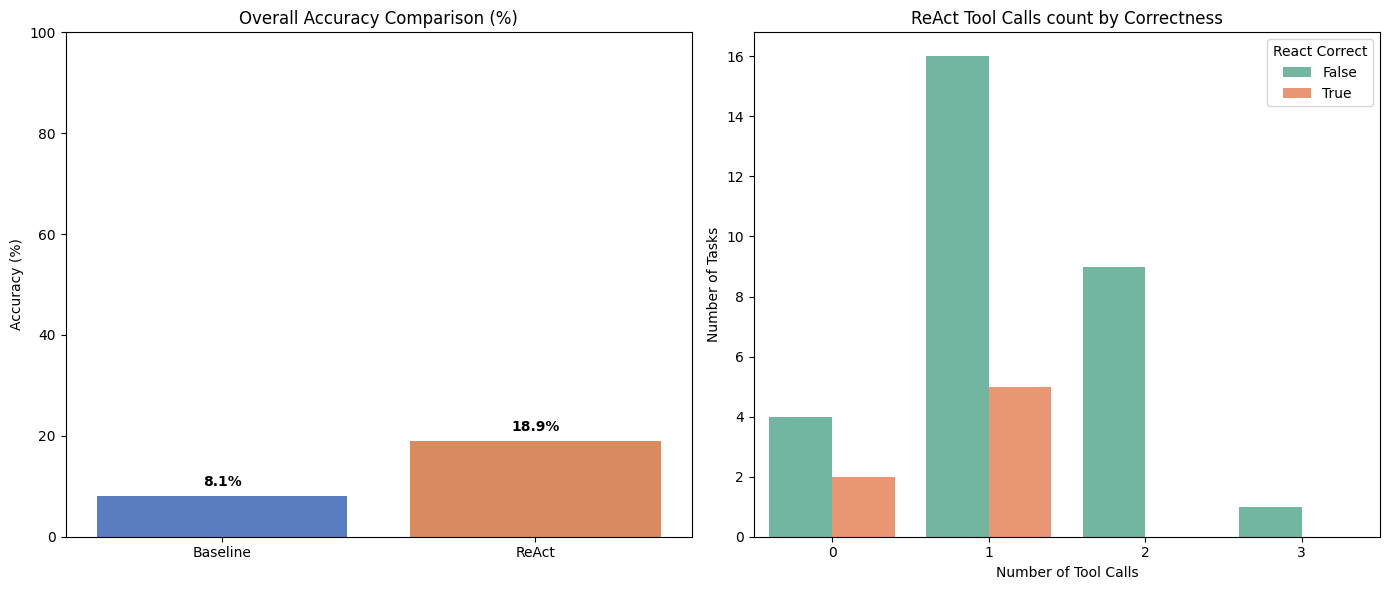

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate accuracies
baseline_accuracy = results_df['baseline_correct'].mean() * 100
react_accuracy = results_df['react_correct'].mean() * 100

print(f"Baseline Accuracy: {baseline_accuracy:.2f}%")
print(f"ReAct Accuracy: {react_accuracy:.2f}%")

# 2. Plotting the comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Accuracy Bar Chart
sns.barplot(
    x=['Baseline', 'ReAct'],
    y=[baseline_accuracy, react_accuracy],
    ax=axes[0],
    palette='muted',
    hue=['Baseline', 'ReAct'],
    legend=False
)
axes[0].set_title('Overall Accuracy Comparison (%)')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_ylim(0, 100)
for i, val in enumerate([baseline_accuracy, react_accuracy]):
    axes[0].text(i, val + 2, f"{val:.1f}%", ha='center', fontweight='bold')

# Distribution of Tool Calls for ReAct
sns.countplot(
    data=results_df,
    x='tool_calls',
    hue='react_correct',
    ax=axes[1],
    palette='Set2'
)
axes[1].set_title('ReAct Tool Calls count by Correctness')
axes[1].set_xlabel('Number of Tool Calls')
axes[1].set_ylabel('Number of Tasks')
axes[1].legend(title='React Correct', labels=['False', 'True'])

plt.tight_layout()
plt.show()